# 01 · 数据：读取、检查、按周汇总

1. 读取 `train.csv`（10 家门店 × 50 种商品 × 5 年的日销量）。
2. 检查数据完整性：有无缺失值、日期是否齐全。
3. 按周汇总，因为订货决策每周做一次。
4. 画图观察趋势和季节性。
5. 保存 `weekly.csv`，供后续 notebook 使用。

运行前请把 `train.csv` 放在与 `notebooks/` 同级的 `data/` 目录中。

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

## 1. 读取数据

In [24]:
df = pd.read_csv(DATA / "train.csv", parse_dates=["date"])
print("行数:", len(df))
df.head()

行数: 913000


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


## 2. 数据检查

预期：913,000 行，10 家门店，50 种商品，1826 天（2013–2017，含一个闰年），无缺失值，无负销量。

In [25]:
print("时间范围:", df["date"].min().date(), "→", df["date"].max().date())
print("门店:", df["store"].nunique(), "| 商品:", df["item"].nunique(), "| 天数:", df["date"].nunique())
print("各列缺失值:")
print(df.isna().sum())
print("负销量:", (df["sales"] < 0).sum())

# 每个“门店 × 商品”应有相同的天数
days_per_series = df.groupby(["store", "item"]).size()
print("每条序列的天数: 最少", days_per_series.min(), "最多", days_per_series.max())

时间范围: 2013-01-01 → 2017-12-31
门店: 10 | 商品: 50 | 天数: 1826
各列缺失值:
date     0
store    0
item     0
sales    0
dtype: int64
负销量: 0
每条序列的天数: 最少 1826 最多 1826


## 3. 按周汇总

每个日期对应到所在周的周一（日期减去星期几，周一为 0），再按“周 × 门店 × 商品”求和。

第一周从周二（2013-01-01）开始，只有 6 天。保留它会低估这一周的销量，所以删除不足 7 天的周。

In [26]:
df["week"] = df["date"] - pd.to_timedelta(df["date"].dt.day_of_week, unit="D")

weekly = (df.groupby(["week", "store", "item"])
            .agg(sales=("sales", "sum"), n_days=("date", "nunique"))
            .reset_index())

print("不完整的周（少于 7 天）:")
print(weekly.loc[weekly["n_days"] < 7, "week"].drop_duplicates().dt.date.tolist())

weekly = weekly[weekly["n_days"] == 7].drop(columns="n_days")
print("剩余周数:", weekly["week"].nunique(), "| 行数:", len(weekly))
weekly.head()

不完整的周（少于 7 天）:
[datetime.date(2012, 12, 31)]
剩余周数: 260 | 行数: 130000


,week,store,item,sales
500,2013-01-07,1,1,66
501,2013-01-07,1,2,211
502,2013-01-07,1,3,116
503,2013-01-07,1,4,79
504,2013-01-07,1,5,65


## 4. 划分训练集、验证集、测试集

按时间顺序划分（不随机打乱），避免用未来数据训练模型（数据泄露）。每周归入其周一所在的年份。

- **训练集** 2013–2015：用于训练模型；
- **验证集** 2016：用于确定参数、估计预测误差；
- **测试集** 2017：最终评估，只计算一次。

In [27]:
def split_of(week):
    if week.year <= 2015:
        return "train"
    if week.year == 2016:
        return "valid"
    return "test"

weekly["split"] = weekly["week"].apply(split_of)
weekly.groupby("split")["week"].nunique()

split
test      52
train    156
valid     52
Name: week, dtype: int64

## 5. 图表

**图 1：** 全部门店和商品的周销量。观察是否逐年增长、是否有重复的季节模式。

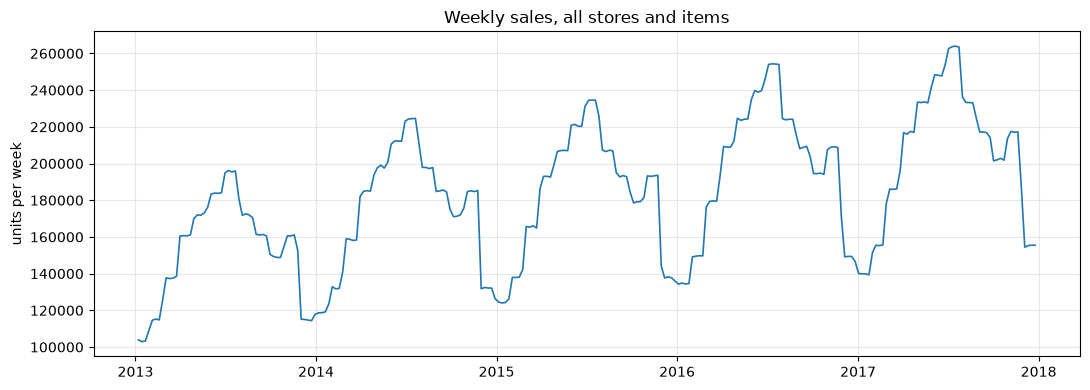

In [28]:
total = weekly.groupby("week")["sales"].sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(total.index, total.values, lw=1.2)
ax.set_title("Weekly sales, all stores and items")
ax.set_ylabel("units per week")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "01_total_weekly.png", dpi=150)
plt.show()

**图 2：** 三条单独的“门店 × 商品”序列。订货决策就是针对这样的序列做的，它们比全网总量波动更大。

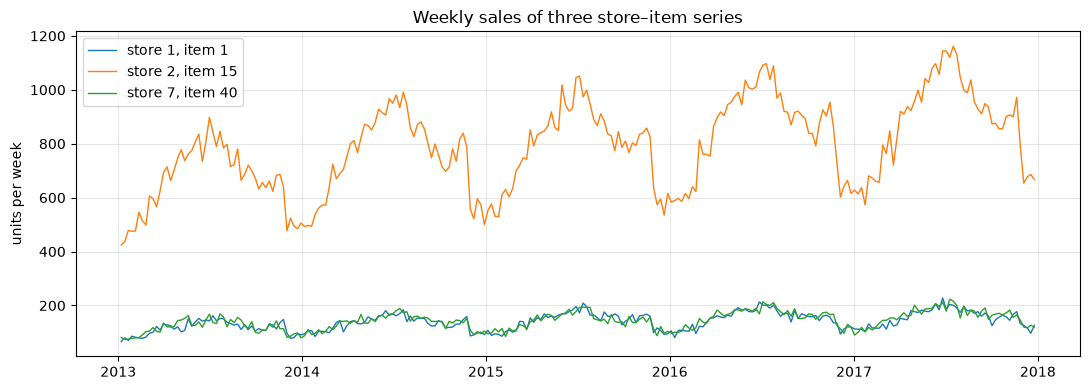

In [29]:
fig, ax = plt.subplots(figsize=(11, 4))
for store, item in [(1, 1), (2, 15), (7, 40)]:
    s = weekly[(weekly["store"] == store) & (weekly["item"] == item)]
    ax.plot(s["week"], s["sales"], lw=1, label=f"store {store}, item {item}")
ax.set_title("Weekly sales of three store–item series")
ax.set_ylabel("units per week")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "01_three_series.png", dpi=150)
plt.show()

**图 3：** 季节性。训练集中每年按“第几周”计算的平均销量。如果各年曲线形状一致，说明季节性稳定，“第几周”是有用的特征。

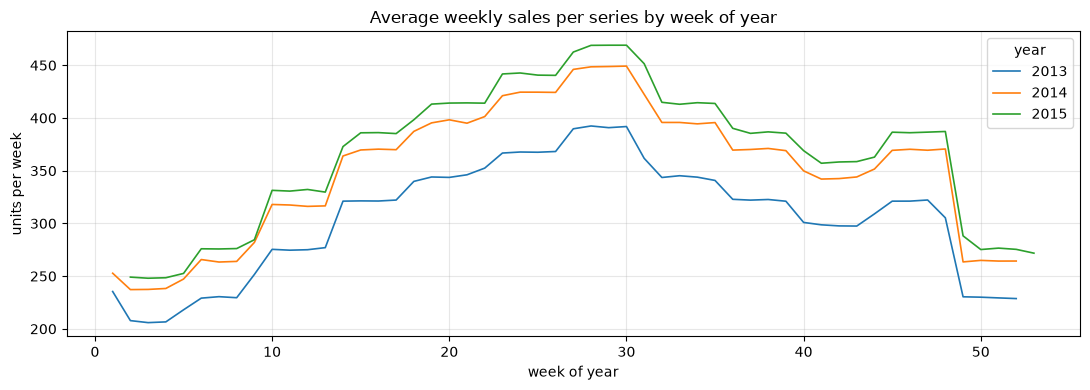

In [30]:
tmp = weekly[weekly["split"] == "train"].copy()
tmp["year"] = tmp["week"].dt.year
tmp["week_of_year"] = tmp["week"].dt.isocalendar().week.astype(int)
season = tmp.groupby(["year", "week_of_year"])["sales"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(11, 4))
season.plot(ax=ax, lw=1.2)
ax.set_title("Average weekly sales per series by week of year")
ax.set_xlabel("week of year")
ax.set_ylabel("units per week")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "01_seasonality.png", dpi=150)
plt.show()

## 6. 保存

In [31]:
weekly.to_csv(DATA / "weekly.csv", index=False)
print("已保存:", DATA / "weekly.csv", "|", len(weekly), "行")

已保存: ../data/weekly.csv | 130000 行


## 小结

- 数据完整，无缺失值和负值，500 条序列均覆盖 1826 天。
- 删除了 2012 年 12 月 31 日开始、只有 6 天的第一周，剩余 260 周。
- 销量逐年增长；每年第 26 至 30 周（7 月）为销售高峰，12 月明显回落。
- 训练集 156 周，验证集和测试集各 52 周。